# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

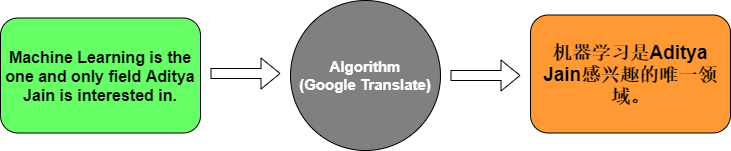

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step - accuracy: 0.1429 - loss: 2.4864 - val_accuracy: 0.0000e+00 - val_loss: 2.4877
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.1429 - loss: 2.4775 - val_accuracy: 0.0000e+00 - val_loss: 2.4896
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.1429 - loss: 2.4684 - val_accuracy: 0.0000e+00 - val_loss: 2.4918
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5714 - loss: 2.4586 - val_accuracy: 0.0000e+00 - val_loss: 2.4941
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5714 - loss: 2.4477 - val_accuracy: 0.0000e+00 - val_loss: 2.4967
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4353 - val_accuracy: 0.0000e+00 - val_loss: 2.4997
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5714 - loss: 2.4207 - val_accuracy: 0.0000e+00 - val_loss: 2.5031
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.5714 - loss: 2.4035 - val_accuracy:

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1. What does the Embedding layer do to a word index?**

It converts each word index into a numerical vector that represents the word.

**2. What is the role of the Encoder LSTM?**

It reads the input sequence and captures important information and context.

**3. What does the Decoder LSTM do?**

It uses the information from the encoder to generate the output sequence step by step.

**4. Why do we use softmax in the final layer?**

It converts the output into probabilities and helps the model choose the most likely word.


### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [8]:
import pandas as pd
import numpy as np
import tensorflow as tf
import re

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [9]:
df = pd.read_csv('/content/eng_-french.csv')

print(df.head())
print(df.columns)
print(df.shape)

  English words/sentences French words/sentences
0                     Hi.                 Salut!
1                    Run!                Cours !
2                    Run!               Courez !
3                    Who?                  Qui ?
4                    Wow!             Ça alors !
Index(['English words/sentences', 'French words/sentences'], dtype='object')
(175621, 2)


In [10]:
df = df.iloc[:, :2].copy()
df.columns = ['English', 'French']

df = df.dropna()
df['English'] = df['English'].astype(str).str.lower().str.strip()
df['French'] = df['French'].astype(str).str.lower().str.strip()

df = df.drop_duplicates()
df = df[(df['English'] != '') & (df['French'] != '')]

df = df.head(10000).reset_index(drop=True)

print(df.head())
print("Dataset shape:", df.shape)

  English      French
0     hi.      salut!
1    run!     cours !
2    run!    courez !
3    who?       qui ?
4    wow!  ça alors !
Dataset shape: (10000, 2)


In [11]:
english_sentences = df['English'].tolist()
french_sentences = ['<start> ' + s + ' <end>' for s in df['French']]

tokenizer_eng = Tokenizer(filters='')
tokenizer_eng.fit_on_texts(english_sentences)

tokenizer_frn = Tokenizer(filters='')
tokenizer_frn.fit_on_texts(french_sentences)

eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

eng_vocab_size = len(tokenizer_eng.word_index) + 1
frn_vocab_size = len(tokenizer_frn.word_index) + 1

print("English vocabulary size:", eng_vocab_size)
print("French vocabulary size:", frn_vocab_size)

English vocabulary size: 2948
French vocabulary size: 5756


In [12]:
max_eng_len = max(len(seq) for seq in eng_sequences)
max_frn_len = max(len(seq) for seq in frn_sequences)

eng_padded = pad_sequences(
    eng_sequences,
    maxlen=max_eng_len,
    padding='post'
)

frn_padded = pad_sequences(
    frn_sequences,
    maxlen=max_frn_len,
    padding='post'
)

print("English padded shape:", eng_padded.shape)
print("French padded shape:", frn_padded.shape)

English padded shape: (10000, 5)
French padded shape: (10000, 12)


In [13]:
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded,
    frn_padded,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(eng_train))
print("Testing samples:", len(eng_test))

Training samples: 8000
Testing samples: 2000


In [14]:
embedding_dim = 128
latent_dim = 128

encoder_inputs = Input(shape=(max_eng_len,))

encoder_embedding = Embedding(
    input_dim=eng_vocab_size,
    output_dim=embedding_dim,
    mask_zero=True
)(encoder_inputs)

encoder_lstm = LSTM(
    latent_dim,
    return_state=True
)

_, state_h, state_c = encoder_lstm(encoder_embedding)

encoder_states = [state_h, state_c]

decoder_inputs = Input(shape=(max_frn_len - 1,))

decoder_embedding_layer = Embedding(
    input_dim=frn_vocab_size,
    output_dim=embedding_dim,
    mask_zero=True
)

decoder_embedding = decoder_embedding_layer(decoder_inputs)

decoder_lstm = LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=encoder_states
)

decoder_dense = Dense(
    frn_vocab_size,
    activation='softmax'
)

decoder_outputs = decoder_dense(decoder_outputs)

model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 5, 128)    │    377,344 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 5)         │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 11, 128)   │    736,768 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 128),     │    131,584 │ embedding_1[0][0… │
│                     │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, 11, 128), │    131,584 │ embedding_2[0][0… │
│                     │ (None, 128),      │            │ lstm_2[0][1],     │
│                     │ (None, 128)]      │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 11, 5756)  │    742,524 │ lstm_3[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,119,804 (8.09 MB)

 Trainable params: 2,119,804 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
decoder_input_data = frn_train[:, :-1]
decoder_target_data = frn_train[:, 1:]

decoder_target_data = np.expand_dims(decoder_target_data, axis=-1)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    [eng_train, decoder_input_data],
    decoder_target_data,
    batch_size=64,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.2671 - loss: 5.8756 - val_accuracy: 0.3677 - val_loss: 4.6538
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.4078 - loss: 4.1827 - val_accuracy: 0.4107 - val_loss: 4.1047
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.4222 - loss: 3.7835 - val_accuracy: 0.4224 - val_loss: 3.8921
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.4412 - loss: 3.5359 - val_accuracy: 0.4438 - val_loss: 3.7254
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.4739 - loss: 3.3073 - val_accuracy: 0.4882 - val_loss: 3.5571
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5150 - loss: 3.1022 - val_accuracy: 0.5200 - val_loss: 3.4317
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5425 - loss: 2.9299 - val_accuracy: 0.5285 - val_loss: 3.3360
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5563 - loss: 2.7823 - val_accu

In [16]:
decoder_test_input = frn_test[:, :-1]
decoder_test_target = np.expand_dims(
    frn_test[:, 1:],
    axis=-1
)

loss, accuracy = model.evaluate(
    [eng_test, decoder_test_input],
    decoder_test_target
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5648 - loss: 3.1254
Test Loss: 3.125375986099243
Test Accuracy: 0.5647528767585754


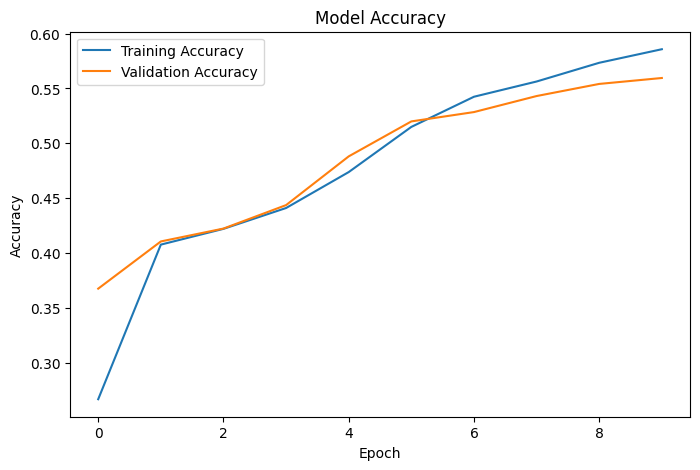

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()

In [23]:
def translate_sentence(sentence):
    sequence = tokenizer_eng.texts_to_sequences([sentence.lower()])
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_eng_len,
        padding='post'
    )

    target_sequence = np.zeros((1, max_frn_len - 1), dtype=np.int32)
    target_sequence[0, 0] = tokenizer_frn.word_index['<start>']

    translated_words = []

    for i in range(max_frn_len - 1):
        predictions = model.predict(
            [padded_sequence, target_sequence],
            verbose=0
        )

        predicted_id = np.argmax(predictions[0, i, :])

        predicted_word = tokenizer_frn.index_word.get(predicted_id, '')

        if predicted_word == '<end>' or predicted_id == 0:
            break

        if predicted_word != '<start>':
            translated_words.append(predicted_word)

        if i + 1 < max_frn_len - 1:
            target_sequence[0, i + 1] = predicted_id

    return ' '.join(translated_words)


print("Translation:", translate_sentence("How are you?"))
print("Translation:", translate_sentence("What is your name?"))

Translation: êtes-vous ?
Translation: qu'est-ce ça ?
